In [1]:
# Iskandar Zulkarnain Wijaya_202331121
import csv
from bs4 import BeautifulSoup
import requests

In [2]:
# Iskandar Zulkarnain Wijaya_202331121
url = "https://id.tradingeconomics.com/country-list/corruption-rank"
headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML,"
        " like Gecko) Chrome/120.0.0.0 Safari/537.36"
    )
}

response = requests.get(url, headers=headers)
print("Status Code:", response.status_code)

Status Code: 200


In [3]:
# Iskandar Zulkarnain Wijaya_202331121
soup = BeautifulSoup(response.text, "html.parser")
table = soup.find("table", class_="table")
rows = table.find_all("tr") if table else []

print(f"Jumlah baris data ditemukan pada tabel: {len(rows)}")

Jumlah baris data ditemukan pada tabel: 181


In [4]:
# Iskandar Zulkarnain Wijaya_202331121
result = []

for row in rows[1:]:
  cols = row.find_all("td")
  if len(cols) >= 4:
    negara = cols[0].get_text(strip=True)
    terakhir = cols[1].get_text(strip=True)
    sebelum_ini = cols[2].get_text(strip=True)
    referensi = cols[3].get_text(strip=True)

    result.append({
        "negara": negara,
        "terakhir": terakhir,
        "sebelum_ini": sebelum_ini,
        "referensi": referensi,
    })

print("Contoh 3 data teratas:", result[:3])

Contoh 3 data teratas: [{'negara': 'Denmark', 'terakhir': '1', 'sebelum_ini': '1', 'referensi': '2025-12'}, {'negara': 'Finlandia', 'terakhir': '2', 'sebelum_ini': '2', 'referensi': '2025-12'}, {'negara': 'Singapura', 'terakhir': '3', 'sebelum_ini': '3', 'referensi': '2025-12'}]


In [5]:
# Iskandar Zulkarnain Wijaya_202331121
filename = "corruption_rank.csv"
with open(filename, "w", newline="", encoding="utf-8") as csvfile:
  fieldnames = ["negara", "terakhir", "sebelum_ini", "referensi"]
  writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

  writer.writeheader()
  for item in result:
    writer.writerow(item)

print(f"Data berhasil disimpan ke file {filename}")

Data berhasil disimpan ke file corruption_rank.csv


In [6]:
# Iskandar Zulkarnain Wijaya_202331121
import pandas as pd
db = pd.read_csv("corruption_rank.csv")

In [7]:
db

,negara,terakhir,sebelum_ini,referensi
0,Denmark,1,1,2025-12
1,Finlandia,2,2,2025-12
2,Singapura,3,3,2025-12
3,Selandia Baru,4,4,2025-12
4,Norwegia,4,5,2025-12
...,...,...,...,...
175,Libya,177,173,2025-12
176,Yaman,177,173,2025-12
177,Venezuela,180,178,2025-12
178,Somalia,181,179,2025-12


In [8]:
# Iskandar Zulkarnain Wijaya_202331121
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [9]:
# Iskandar Zulkarnain Wijaya_202331121
df = pd.read_csv("corruption_rank.csv")
print("Informasi Dataset:")
print(df.info())
print("\nCuplikan Data:")
print(df.head())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   negara       180 non-null    object
 1   terakhir     180 non-null    int64 
 2   sebelum_ini  180 non-null    int64 
 3   referensi    180 non-null    object
dtypes: int64(2), object(2)
memory usage: 5.8+ KB
None

Cuplikan Data:
          negara  terakhir  sebelum_ini referensi
0        Denmark         1            1   2025-12
1      Finlandia         2            2   2025-12
2      Singapura         3            3   2025-12
3  Selandia Baru         4            4   2025-12
4       Norwegia         4            5   2025-12


In [10]:
# Iskandar Zulkarnain Wijaya_202331121
df["terakhir"] = pd.to_numeric(df["terakhir"], errors="coerce")
df["sebelum_ini"] = pd.to_numeric(df["sebelum_ini"], errors="coerce")
df_clean = df.dropna(subset=["terakhir", "sebelum_ini"])
print(f"Jumlah data setelah dibersihkan: {len(df_clean)} baris")

Jumlah data setelah dibersihkan: 180 baris


In [11]:
# Iskandar Zulkarnain Wijaya_202331121
X = df_clean[["sebelum_ini"]]
y = df_clean["terakhir"]

print("Fitur (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Fitur (X) shape: (180, 1)
Target (y) shape: (180,)


In [12]:
# Iskandar Zulkarnain Wijaya_202331121
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Jumlah data latih: {len(X_train)} baris")
print(f"Jumlah data uji: {len(X_test)} baris")

Jumlah data latih: 144 baris
Jumlah data uji: 36 baris


In [13]:
# Iskandar Zulkarnain Wijaya_202331121
model = LinearRegression()
model.fit(X_train, y_train)
print("Koefisien (Slope):", model.coef_[0])
print("Intercept:", model.intercept_)

Koefisien (Slope): 1.0079956956885434
Intercept: 0.2578327590981502


In [14]:
# Iskandar Zulkarnain Wijaya_202331121
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")

Mean Squared Error (MSE): 36.5268
R-squared Score (R2): 0.9858


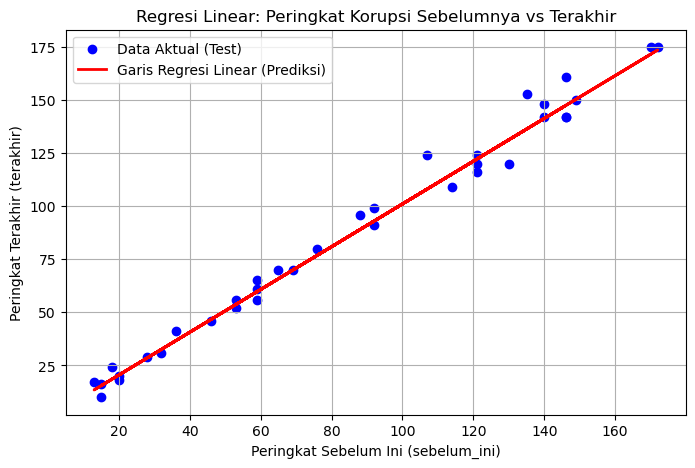

In [15]:
# Iskandar Zulkarnain Wijaya_202331121
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="blue", label="Data Aktual (Test)")
plt.plot(
    X_test,
    y_pred,
    color="red",
    linewidth=2,
    label="Garis Regresi Linear (Prediksi)",
)
plt.title("Regresi Linear: Peringkat Korupsi Sebelumnya vs Terakhir")
plt.xlabel("Peringkat Sebelum Ini (sebelum_ini)")
plt.ylabel("Peringkat Terakhir (terakhir)")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

In [17]:
# Iskandar Zulkarnain Wijaya_202331121
df = pd.read_csv("corruption_rank.csv")
print("Informasi Dataset:")
print(df.info())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   negara       180 non-null    object
 1   terakhir     180 non-null    int64 
 2   sebelum_ini  180 non-null    int64 
 3   referensi    180 non-null    object
dtypes: int64(2), object(2)
memory usage: 5.8+ KB
None


In [18]:
# Iskandar Zulkarnain Wijaya_202331121
# Membersihkan dan memastikan kolom numerik bersih dari nilai non-angka
df["terakhir"] = pd.to_numeric(df["terakhir"], errors="coerce")
df["sebelum_ini"] = pd.to_numeric(df["sebelum_ini"], errors="coerce")

# Menghapus baris dengan nilai kosong (NaN)
df_clean = df.dropna(subset=["terakhir", "sebelum_ini"])

print(f"Jumlah data siap pakai: {len(df_clean)} baris")

Jumlah data siap pakai: 180 baris


In [19]:
# Iskandar Zulkarnain Wijaya_202331121
X = df_clean[["sebelum_ini"]]
y = df_clean["terakhir"]

print("Fitur (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Fitur (X) shape: (180, 1)
Target (y) shape: (180,)


In [20]:
# Iskandar Zulkarnain Wijaya_202331121
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Data Latih: {len(X_train)} baris")
print(f"Data Uji: {len(X_test)} baris")

Data Latih: 144 baris
Data Uji: 36 baris


In [21]:
# Iskandar Zulkarnain Wijaya_202331121
# Mengatur max_depth agar pohon keputusan tidak terlalu kompleks (overfitting)
tree_model = DecisionTreeRegressor(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih!")

Model Decision Tree berhasil dilatih!


In [22]:
# Iskandar Zulkarnain Wijaya_202331121
y_pred = tree_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")

Mean Squared Error (MSE): 49.1994
R-squared Score (R2): 0.9809


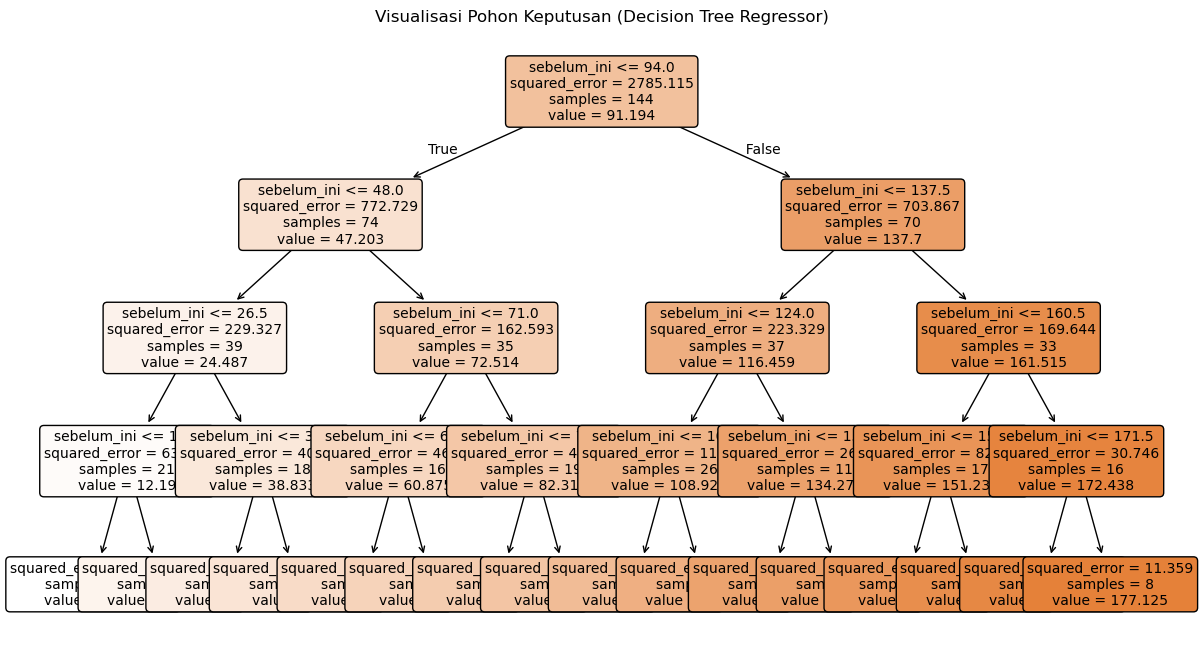

In [23]:
# Iskandar Zulkarnain Wijaya_202331121
plt.figure(figsize=(14, 8))
plot_tree(
    tree_model,
    feature_names=["sebelum_ini"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Visualisasi Pohon Keputusan (Decision Tree Regressor)")
plt.show()